In [ ]:
!pip install scikit-learn joblib -q

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import json
import joblib
import io
import warnings
from sklearn.ensemble import IsolationForest
from sklearn.preprocessing import MinMaxScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import silhouette_score

warnings.filterwarnings('ignore')
np.random.seed(42)

print("All libraries imported successfully")
print(f"scikit-learn: {__import__('sklearn').__version__}")


All libraries imported successfully
scikit-learn: 1.6.1


In [ ]:
from google.colab import files

print("Upload your TWO CSV files.")
print("Hold Ctrl and click both files together.\n")

uploaded = files.upload()

if len(uploaded) == 0:
    raise ValueError("No files uploaded. Run this cell again.")

if len(uploaded) < 2:
    print(f"WARNING: Only {len(uploaded)} file uploaded.")
    print("For best results upload both CSV files.")

dfs = []
for filename, content in uploaded.items():
    df_temp = pd.read_csv(io.BytesIO(content))
    print(f"Loaded: {filename} — {df_temp.shape[0]} rows, {df_temp.shape[1]} columns")
    dfs.append(df_temp)

combined_df = pd.concat(dfs, ignore_index=True)
print(f"\nCombined: {combined_df.shape[0]} rows x {combined_df.shape[1]} columns")



Upload your TWO CSV files.
Hold Ctrl and click both files together.



Saving rig_sensor_dataset_15_20min.csv to rig_sensor_dataset_15_20min.csv
Saving Rig_sensor_dataset_16_30min.csv to Rig_sensor_dataset_16_30min.csv
Loaded: rig_sensor_dataset_15_20min.csv — 1000 rows, 12 columns
Loaded: Rig_sensor_dataset_16_30min.csv — 2500 rows, 11 columns

Combined: 3500 rows x 12 columns


In [ ]:
print("=" * 55)
print("DATASET OVERVIEW")
print("=" * 55)
print(f"Rows    : {combined_df.shape[0]}")
print(f"Columns : {combined_df.shape[1]}")

print("\nColumn names and types:")
for col in combined_df.columns:
    print(f"  {col:<30} [{combined_df[col].dtype}]")

print("\nFirst 5 rows:")
print(combined_df.head())

print("\nMissing values:")
missing = combined_df.isnull().sum()
if missing.sum() == 0:
    print("  None found.")
else:
    print(missing[missing > 0].to_string())

DATASET OVERVIEW
Rows    : 3500
Columns : 12

Column names and types:
  speed_rpm                      [int64]
  vib_rms_g                      [float64]
  vib_peak_g                     [float64]
  vib_kurtosis                   [float64]
  vib_firing_band_g              [float64]
  vib_hf_band_g                  [float64]
  temp_coolant_C                 [float64]
  temp_oil_C                     [float64]
  temp_block_C                   [float64]
  temp_ambient_C                 [float64]
  current_A                      [float64]
  condition                      [object]

First 5 rows:
   speed_rpm  vib_rms_g  vib_peak_g  vib_kurtosis  vib_firing_band_g  \
0        992     0.1746      0.6372         2.803             0.0383   
1       1015     0.1990      0.7161         2.695             0.0413   
2        998     0.1849      0.6536         3.031             0.0439   
3        995     0.1802      0.6759         2.903             0.0425   
4        996     0.1958      0.6922       

In [ ]:
# ALL non-sensor columns are excluded here.
# condition column is excluded along with all other non-numeric
# and identifier columns.
# It is not stored, not used for training, not used for evaluation.

EXCLUDE_PATTERNS = [
    'condition', 'label', 'status', 'source_file', '_source_file',
    'timestamp', 'time', 'datetime', 'date', 'id', 'index',
    'session', 'run', 'class', 'target', 'fault', 'anomaly',
    'health', 'health_score', 'rul', 'remaining'
]

def is_excluded(col_name):
    col_lower = col_name.lower().strip()
    return any(excl in col_lower for excl in EXCLUDE_PATTERNS)

# Keep only numeric sensor columns
numeric_cols = combined_df.select_dtypes(include=[np.number]).columns.tolist()
FEATURE_COLS = [c for c in numeric_cols if not is_excluded(c)]

# Log what was excluded so user knows
excluded_found = [c for c in combined_df.columns if is_excluded(c)]
print(f"Excluded columns (not used anywhere): {excluded_found}")
print()
print(f"Selected sensor features ({len(FEATURE_COLS)}):")
for i, f in enumerate(FEATURE_COLS, 1):
    print(f"  {i:2d}. {f}")

if len(FEATURE_COLS) == 0:
    raise ValueError(
        "No numeric sensor features found.\n"
        "Check your CSV column names."
    )


Excluded columns (not used anywhere): ['condition']

Selected sensor features (11):
   1. speed_rpm
   2. vib_rms_g
   3. vib_peak_g
   4. vib_kurtosis
   5. vib_firing_band_g
   6. vib_hf_band_g
   7. temp_coolant_C
   8. temp_oil_C
   9. temp_block_C
  10. temp_ambient_C
  11. current_A


In [ ]:
# Work only with sensor feature columns from this point.
# condition column is not carried forward at all.
X = combined_df[FEATURE_COLS].copy()
before = len(X)

X.dropna(inplace=True)
X.reset_index(drop=True, inplace=True)
after = len(X)

print(f"Rows before cleaning : {before}")
print(f"Rows after cleaning  : {after}")
print(f"Rows removed         : {before - after}")
print(f"Feature matrix shape : {X.shape}")
print()
print("Sensor feature statistics:")
print(X.describe().round(3).to_string())


Rows before cleaning : 3500
Rows after cleaning  : 3500
Rows removed         : 0
Feature matrix shape : (3500, 11)

Sensor feature statistics:
       speed_rpm  vib_rms_g  vib_peak_g  vib_kurtosis  vib_firing_band_g  vib_hf_band_g  temp_coolant_C  temp_oil_C  temp_block_C  temp_ambient_C  current_A
count   3500.000   3500.000    3500.000      3500.000           3500.000       3500.000        3500.000    3500.000      3500.000        3500.000   3500.000
mean    1507.207      0.320       1.443         3.775              0.097          0.025          84.943     105.972       107.208          24.402      9.495
std      372.343      0.099       0.668         1.200              0.038          0.015           6.194      10.240         9.492           1.705      2.893
min        0.000      0.007       0.021         2.410              0.000          0.001          27.650      26.830        27.500          21.130      0.000
25%     1250.000      0.256       0.956         2.891              0.072

In [ ]:
TEST_SIZE   = 0.20
RANDOM_SEED = 42

X_train, X_test = train_test_split(
    X,
    test_size=TEST_SIZE,
    random_state=RANDOM_SEED
)

print(f"Training set : {X_train.shape[0]} rows (80%)")
print(f"Test set     : {X_test.shape[0]} rows (20%)")
print()
print("Condition column: NOT included in split.")



Training set : 2800 rows (80%)
Test set     : 700 rows (20%)

Condition column: NOT included in split.


In [ ]:
scaler = MinMaxScaler()

# Fit ONLY on training data
X_train_scaled = scaler.fit_transform(X_train)

# Transform test using same scaler — no refitting
X_test_scaled = scaler.transform(X_test)

print("MinMaxScaler fitted on training data only.")
print(f"Train range: [{X_train_scaled.min():.3f}, {X_train_scaled.max():.3f}]")
print(f"Test range : [{X_test_scaled.min():.3f}, {X_test_scaled.max():.3f}]")



MinMaxScaler fitted on training data only.
Train range: [0.000, 1.000]
Test range : [0.000, 1.012]


hyper parameter

In [ ]:
# ── CELL 7B — Hyperparameter Tuning for Isolation Forest ───────
# Run this INSTEAD of Cell 8 (replaces fixed CONTAMINATION and IF training)
# Finds best: n_estimators, contamination, max_features

from sklearn.metrics import silhouette_score
import itertools

print("Tuning Isolation Forest hyperparameters...")
print("Testing combinations — takes 2-3 minutes\n")

param_grid = {
    'n_estimators'  : [100, 200, 300],
    'contamination' : [0.03, 0.05, 0.08, 0.10],
    'max_features'  : [0.6, 0.8, 1.0]
}

best_score  = -1
best_params = {}
results_log = []

combos = list(itertools.product(
    param_grid['n_estimators'],
    param_grid['contamination'],
    param_grid['max_features']
))

print(f"Total combinations to test: {len(combos)}\n")

for i, (n_est, cont, max_feat) in enumerate(combos):
    clf = IsolationForest(
        n_estimators=n_est,
        contamination=cont,
        max_features=max_feat,
        max_samples='auto',
        random_state=42,
        n_jobs=-1
    )
    clf.fit(X_train_scaled)
    preds  = clf.predict(X_test_scaled)
    binary = np.where(preds == 1, 0, 1)

    if len(np.unique(binary)) < 2:
        continue  # skip if all same class

    sil = silhouette_score(
        X_test_scaled, binary,
        sample_size=min(1000, len(X_test_scaled)),
        random_state=42
    )

    results_log.append({
        'n_estimators': n_est,
        'contamination': cont,
        'max_features': max_feat,
        'silhouette': round(sil, 4),
        'anomaly_pct': round(binary.mean() * 100, 2)
    })

    if sil > best_score:
        best_score  = sil
        best_params = {
            'n_estimators': n_est,
            'contamination': cont,
            'max_features': max_feat
        }

    print(f"[{i+1}/{len(combos)}] n={n_est} cont={cont} feat={max_feat} → sil={sil:.4f}")

print(f"\nBest silhouette : {best_score:.4f}  (previous: 0.3968)")
print(f"Best params     : {best_params}")

# Show top 5
results_df_tune = pd.DataFrame(results_log).sort_values('silhouette', ascending=False)
print("\nTop 5 combinations:")
print(results_df_tune.head(5).to_string(index=False))

# Train final IF with best params
CONTAMINATION = best_params['contamination']

iso_forest = IsolationForest(
    n_estimators=best_params['n_estimators'],
    contamination=best_params['contamination'],
    max_features=best_params['max_features'],
    max_samples='auto',
    random_state=42,
    n_jobs=-1
)
iso_forest.fit(X_train_scaled)
print(f"\nFinal Isolation Forest trained with best parameters.")

Tuning Isolation Forest hyperparameters...
Testing combinations — takes 2-3 minutes

Total combinations to test: 36

[1/36] n=100 cont=0.03 feat=0.6 → sil=0.4869
[2/36] n=100 cont=0.03 feat=0.8 → sil=0.4481
[3/36] n=100 cont=0.03 feat=1.0 → sil=0.4346
[4/36] n=100 cont=0.05 feat=0.6 → sil=0.4202
[5/36] n=100 cont=0.05 feat=0.8 → sil=0.3981
[6/36] n=100 cont=0.05 feat=1.0 → sil=0.3994
[7/36] n=100 cont=0.08 feat=0.6 → sil=0.3751
[8/36] n=100 cont=0.08 feat=0.8 → sil=0.3510
[9/36] n=100 cont=0.08 feat=1.0 → sil=0.3711
[10/36] n=100 cont=0.1 feat=0.6 → sil=0.3442
[11/36] n=100 cont=0.1 feat=0.8 → sil=0.3219
[12/36] n=100 cont=0.1 feat=1.0 → sil=0.3464
[13/36] n=200 cont=0.03 feat=0.6 → sil=0.4787
[14/36] n=200 cont=0.03 feat=0.8 → sil=0.4723
[15/36] n=200 cont=0.03 feat=1.0 → sil=0.4348
[16/36] n=200 cont=0.05 feat=0.6 → sil=0.4205
[17/36] n=200 cont=0.05 feat=0.8 → sil=0.4120
[18/36] n=200 cont=0.05 feat=1.0 → sil=0.3968
[19/36] n=200 cont=0.08 feat=0.6 → sil=0.3662
[20/36] n=200 cont=0.

In [ ]:
if_preds_raw  = iso_forest.predict(X_test_scaled)   # 1=normal, -1=anomaly
if_scores     = iso_forest.score_samples(X_test_scaled)
if_binary     = np.where(if_preds_raw == 1, 0, 1)   # 0=normal, 1=anomaly

normal_count  = (if_binary == 0).sum()
anomaly_count = (if_binary == 1).sum()
anomaly_pct   = anomaly_count / len(if_binary) * 100

print("=" * 45)
print("ISOLATION FOREST — TEST SET RESULTS")
print("=" * 45)
print(f"Total readings   : {len(if_binary)}")
print(f"Normal           : {normal_count} ({100 - anomaly_pct:.1f}%)")
print(f"Anomalies        : {anomaly_count} ({anomaly_pct:.1f}%)")
print(f"Score range      : [{if_scores.min():.4f}, {if_scores.max():.4f}]")
print(f"(Lower score = more anomalous)")



ISOLATION FOREST — TEST SET RESULTS
Total readings   : 700
Normal           : 684 (97.7%)
Anomalies        : 16 (2.3%)
Score range      : [-0.7103, -0.3832]
(Lower score = more anomalous)


In [ ]:
evaluation_results = {
    "model": "Isolation Forest",
    "n_estimators": int(iso_forest.n_estimators),
    "contamination": CONTAMINATION,
    "test_samples": int(len(if_binary)),
    "normal_count": int(normal_count),
    "anomaly_count": int(anomaly_count),
    "anomaly_percentage": round(float(anomaly_pct), 2),
    "condition_column_used": False,
    "evaluation_type": "unsupervised only"
}

print("UNSUPERVISED EVALUATION METRICS")
print("-" * 45)

# Silhouette score
sil = None
if len(np.unique(if_binary)) > 1:
    sample_size = min(2000, len(X_test_scaled))
    sil = silhouette_score(
        X_test_scaled, if_binary,
        sample_size=sample_size,
        random_state=RANDOM_SEED
    )
    print(f"Silhouette Score : {sil:.4f}")
    print(f"  Range -1 to 1. Above 0.3 = good cluster separation.")
    evaluation_results['silhouette_score'] = round(float(sil), 4)
else:
    print("All predictions same class — silhouette score not applicable.")

# Score separation
if normal_count > 0 and anomaly_count > 0:
    normal_mean  = if_scores[if_binary == 0].mean()
    anomaly_mean = if_scores[if_binary == 1].mean()
    separation   = abs(normal_mean - anomaly_mean)
    print(f"\nNormal mean score  : {normal_mean:.4f}")
    print(f"Anomaly mean score : {anomaly_mean:.4f}")
    print(f"Score separation   : {separation:.4f}")
    print(f"  Higher = model separates normal vs anomaly more clearly.")
    evaluation_results.update({
        'normal_mean_score':  round(float(normal_mean), 4),
        'anomaly_mean_score': round(float(anomaly_mean), 4),
        'score_separation':   round(float(separation), 4)
    })

print("\nCondition column: NOT USED in evaluation.")


UNSUPERVISED EVALUATION METRICS
---------------------------------------------
Silhouette Score : 0.4869
  Range -1 to 1. Above 0.3 = good cluster separation.

Normal mean score  : -0.4452
Anomaly mean score : -0.6422
Score separation   : 0.1971
  Higher = model separates normal vs anomaly more clearly.

Condition column: NOT USED in evaluation.


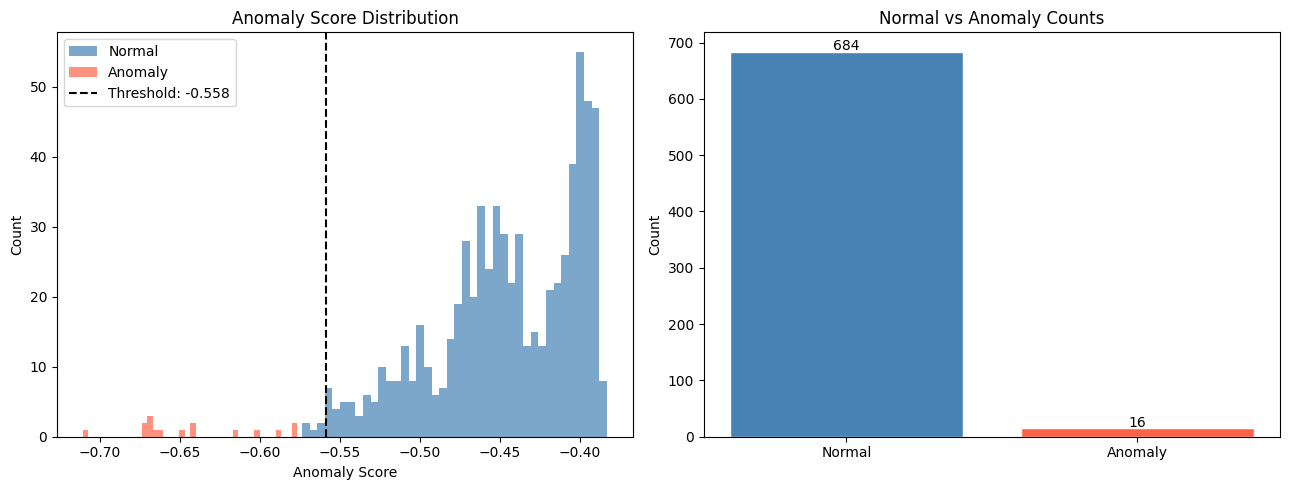

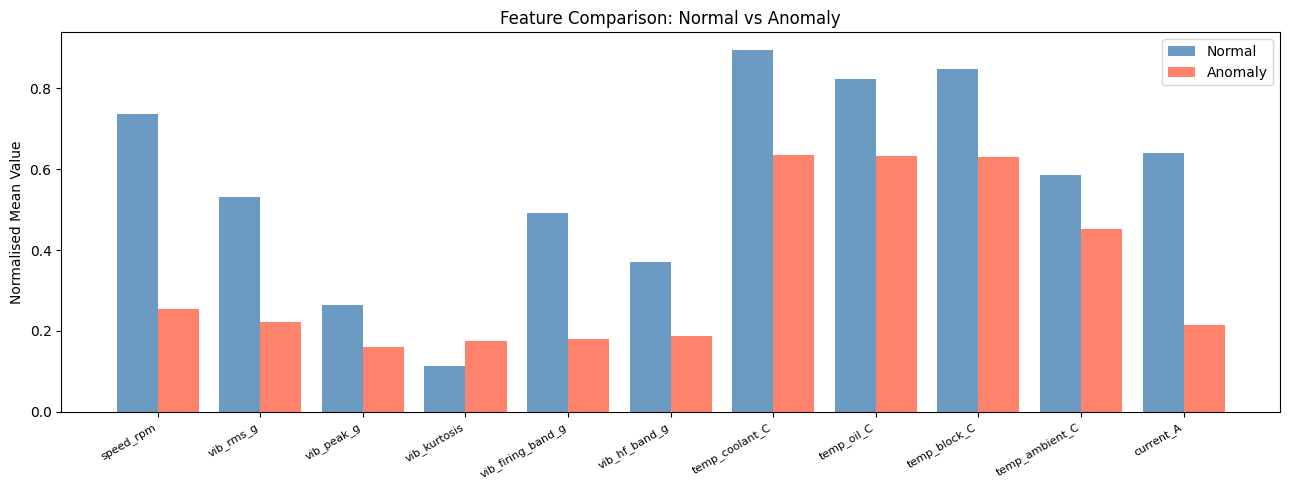

In [ ]:
# Plot 1 — Anomaly score distribution
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

axes[0].hist(if_scores[if_binary == 0], bins=40,
             color='steelblue', alpha=0.7, label='Normal')
if anomaly_count > 0:
    axes[0].hist(if_scores[if_binary == 1], bins=40,
                 color='tomato', alpha=0.7, label='Anomaly')
threshold = np.percentile(if_scores, int(CONTAMINATION * 100))
axes[0].axvline(threshold, color='black', linestyle='--',
                linewidth=1.5, label=f'Threshold: {threshold:.3f}')
axes[0].set_xlabel('Anomaly Score')
axes[0].set_ylabel('Count')
axes[0].set_title('Anomaly Score Distribution')
axes[0].legend()

# Plot 2 — Counts
axes[1].bar(['Normal', 'Anomaly'],
            [normal_count, anomaly_count],
            color=['steelblue', 'tomato'], edgecolor='white')
axes[1].text(0, normal_count  + 2, str(normal_count),  ha='center')
axes[1].text(1, anomaly_count + 2, str(anomaly_count), ha='center')
axes[1].set_title('Normal vs Anomaly Counts')
axes[1].set_ylabel('Count')
plt.tight_layout()
plt.savefig('if_anomaly_distribution.png', dpi=150)
plt.show()

# Plot 3 — Feature comparison
if anomaly_count > 0:
    X_test_df     = pd.DataFrame(X_test_scaled, columns=FEATURE_COLS)
    normal_means  = X_test_df[if_binary == 0].mean()
    anomaly_means = X_test_df[if_binary == 1].mean()
    x_pos = np.arange(len(FEATURE_COLS))
    fig, ax = plt.subplots(figsize=(13, 5))
    ax.bar(x_pos - 0.2, normal_means,  width=0.4,
           color='steelblue', label='Normal',  alpha=0.8)
    ax.bar(x_pos + 0.2, anomaly_means, width=0.4,
           color='tomato',    label='Anomaly', alpha=0.8)
    ax.set_xticks(x_pos)
    ax.set_xticklabels(FEATURE_COLS, rotation=30, ha='right', fontsize=8)
    ax.set_ylabel('Normalised Mean Value')
    ax.set_title('Feature Comparison: Normal vs Anomaly')
    ax.legend()
    plt.tight_layout()
    plt.savefig('if_feature_comparison.png', dpi=150)
    plt.show()


In [ ]:
# 1. Isolation Forest model
joblib.dump(iso_forest, 'isolation_forest.pkl')
print("Saved: isolation_forest.pkl")

# 2. Scaler
joblib.dump(scaler, 'scaler.pkl')
print("Saved: scaler.pkl")

# 3. Feature columns
feature_metadata = {
    "feature_columns": FEATURE_COLS,
    "n_features": len(FEATURE_COLS),
    "contamination": CONTAMINATION,
    "scaler": "MinMaxScaler",
    "condition_column_used": False,
    "note": (
        "Exact feature names and order used during training. "
        "Apply the same scaler to new data before predicting. "
        "Condition column was excluded and must not be included."
    )
}
with open('feature_columns.json', 'w') as f:
    json.dump(feature_metadata, f, indent=2)
print("Saved: feature_columns.json")

# 4. Evaluation results
with open('isolation_forest_evaluation.json', 'w') as f:
    json.dump(evaluation_results, f, indent=2)
print("Saved: isolation_forest_evaluation.json")


Saved: isolation_forest.pkl
Saved: scaler.pkl
Saved: feature_columns.json
Saved: isolation_forest_evaluation.json


In [ ]:
download_files = [
    'isolation_forest.pkl',
    'scaler.pkl',
    'feature_columns.json',
    'isolation_forest_evaluation.json',
    'if_anomaly_distribution.png',
]
if anomaly_count > 0:
    download_files.append('if_feature_comparison.png')

for fname in download_files:
    try:
        files.download(fname)
        print(f"Download ready: {fname}")
    except Exception as e:
        print(f"Could not download {fname}: {e}")



<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Download ready: isolation_forest.pkl


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Download ready: scaler.pkl


... (8 outputs left out)

Download ready: if_anomaly_distribution.png


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Download ready: if_feature_comparison.png


In [ ]:
print("\n" + "=" * 55)
print("NOTEBOOK 1 COMPLETE — SUMMARY")
print("=" * 55)
print(f"  Dataset rows      : {len(X)}")
print(f"  Sensor features   : {len(FEATURE_COLS)}")
print(f"  Feature list      : {FEATURE_COLS}")
print(f"  Training rows     : {X_train_scaled.shape[0]}")
print(f"  Test rows         : {X_test_scaled.shape[0]}")
print(f"  Contamination     : {CONTAMINATION}")
print(f"  Condition column  : NOT USED ANYWHERE")
print()
print(f"  Normal readings   : {normal_count}")
print(f"  Anomaly readings  : {anomaly_count}")
print(f"  Anomaly rate      : {anomaly_pct:.1f}%")
if sil:
    print(f"  Silhouette score  : {sil:.4f}")
print()
print("FILES SAVED:")
for fname in download_files:
    print(f"  - {fname}")
print()
print("NEXT STEP: Run Notebook 2 (LSTM Health Prediction).")
print("Upload the same CSV files to Notebook 2.")
print("=" * 55)



NOTEBOOK 1 COMPLETE — SUMMARY
  Dataset rows      : 3500
  Sensor features   : 11
  Feature list      : ['speed_rpm', 'vib_rms_g', 'vib_peak_g', 'vib_kurtosis', 'vib_firing_band_g', 'vib_hf_band_g', 'temp_coolant_C', 'temp_oil_C', 'temp_block_C', 'temp_ambient_C', 'current_A']
  Training rows     : 2800
  Test rows         : 700
  Contamination     : 0.03
  Condition column  : NOT USED ANYWHERE

  Normal readings   : 684
  Anomaly readings  : 16
  Anomaly rate      : 2.3%
  Silhouette score  : 0.4869

FILES SAVED:
  - isolation_forest.pkl
  - scaler.pkl
  - feature_columns.json
  - isolation_forest_evaluation.json
  - if_anomaly_distribution.png
  - if_feature_comparison.png

NEXT STEP: Run Notebook 2 (LSTM Health Prediction).
Upload the same CSV files to Notebook 2.
